# Pobranie i przygotowanie danych

In [45]:
import urllib
import zipfile
import os
from tqdm import tqdm
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass
import numpy as np
from typing import Optional

In [46]:
urls = [
    "https://sci2s.ugr.es/keel/dataset/data/regression/stock.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/treasury.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/mortgage.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/pole.zip",
]

os.makedirs("data", exist_ok=True)

for _, url in enumerate(tqdm(urls)):
    file_name = url.split('/')[-1]
    file_path = os.path.join("data", file_name)
    urllib.request.urlretrieve(url, file_path)
    extract_folder = os.path.join("data", file_name.replace('.zip', ''))
    with zipfile.ZipFile(file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_folder)

DATASETS_PATHS = {
    "stock": os.path.join("data", "stock", "stock.dat"),
    "treasury": os.path.join("data", "treasury", "treasury.dat"),
    "mortgage": os.path.join("data", "mortgage", "mortgage.dat"),
    "pole": os.path.join("data", "pole", "pole.dat"),
}


100%|██████████| 4/4 [00:01<00:00,  2.61it/s]


In [47]:
def prepare_keel_data(name, filepath, test_size=0.2, random_state=42):
    attributes = []
    outputs = []

    with open(filepath, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith('@attribute'):
                attr_name = line.split()[1]
                attributes.append(attr_name)

            elif line.startswith('@outputs'):
                outputs_str = line.replace('@outputs', '').strip()
                outputs = [out.strip() for out in outputs_str.split(',')]

            elif line.startswith('@data'):
                break

    df = pd.read_csv(filepath, comment='@', header=None)
    df.columns = attributes
    X = df.drop(columns=outputs)
    if len(outputs) == 1:
        y = df[outputs[0]]
    else:
        raise ValueError("Multiple outputs are not supported in this implementation.")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    return df, attributes, outputs[0], X_train, X_test, y_train, y_test

In [48]:
DATASETS = {}

for name, path in DATASETS_PATHS.items():
    df, attributes, output, X_train, X_test, y_train, y_test = prepare_keel_data(name, path)
    DATASETS[name] = {
        'df': df,
        'attributes': attributes,
        'output': output,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    print(f"[{name.upper()}] Train size: {X_train.shape}, Test size: {X_test.shape}, Output train size: {y_train.shape}, Output test size: {y_test.shape}")

# stock_X_train = DATASETS['stock']['X_train']

[STOCK] Train size: (760, 9), Test size: (190, 9), Output train size: (760,), Output test size: (190,)
[TREASURY] Train size: (839, 15), Test size: (210, 15), Output train size: (839,), Output test size: (210,)
[MORTGAGE] Train size: (839, 15), Test size: (210, 15), Output train size: (839,), Output test size: (210,)
[POLE] Train size: (11998, 26), Test size: (3000, 26), Output train size: (11998,), Output test size: (3000,)


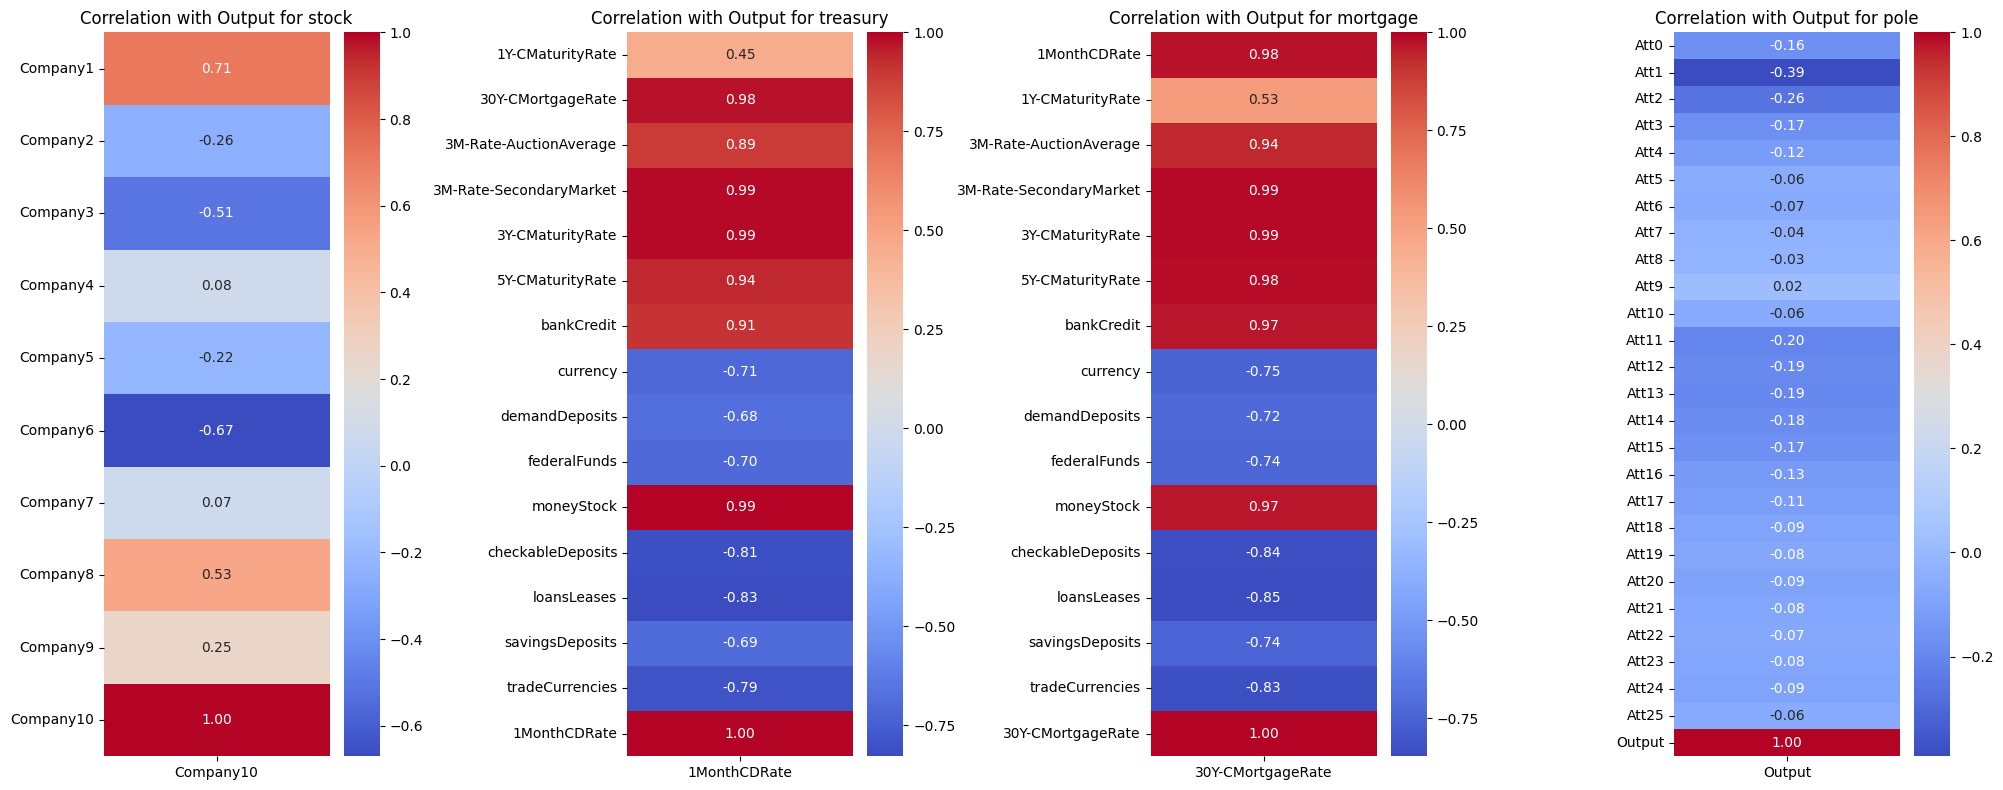

In [49]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 8))
for i, (name, data) in enumerate(DATASETS.items()):
    sns.heatmap(data['df'].corr()[[data['output']]], annot=True, cmap='coolwarm', fmt=".2f", ax=axes[i])
    axes[i].set_title(f'Correlation with Output for {name}')
plt.tight_layout()
plt.show()

In [50]:
print(DATASETS['stock'])

{'df':      Company1  Company2  Company3  Company4  Company5  Company6  Company7  \
0      17.219    50.500    18.750    43.000    60.875    26.375    67.750   
1      17.891    51.375    19.625    44.000    62.000    26.125    68.125   
2      18.438    50.875    19.875    43.875    61.875    27.250    68.500   
3      18.672    51.500    20.000    44.000    62.625    27.875    69.375   
4      17.438    49.000    20.000    41.375    59.750    25.875    63.250   
..        ...       ...       ...       ...       ...       ...       ...   
945    50.375    46.250    19.375    52.250    61.875    23.500    78.625   
946    50.750    46.375    19.625    50.875    64.625    23.250    77.625   
947    50.625    46.625    19.625    50.875    64.625    23.250    75.000   
948    50.125    47.000    19.875    50.750    62.750    22.875    74.500   
949    49.000    47.000    19.500    49.500    60.875    22.750    75.625   

     Company8  Company9  Company10  
0      19.000    48.750     34.

# Implementacja Modelu Lasu Losowego

In [102]:
@dataclass(slots=True, init=False)
class TreeRegressorNode:
    max_depth: int
    min_samples_split: int
    left: Optional["TreeRegressorNode"]
    right: Optional["TreeRegressorNode"]
    feature_index: Optional[int]
    threshold: Optional[float]
    value: Optional[float]
    values: Optional[np.ndarray]

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.left = None
        self.right = None
        self.feature_index = None
        self.threshold = None
        self.value = None
        self.values = None

    def __str__(self):
        return self._get_repr()

    @property
    def is_leaf(self) -> bool:
        return self.left is None and self.right is None

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        self._build_tree(X, y)

    def _build_tree(self, X: np.ndarray, y: np.ndarray, depth=0) -> None:
        if depth >= self.max_depth or len(X) < self.min_samples_split:
            self.value = np.mean(y)
            self.values = y
            return
        best_stddev = float('inf')
        _, n_features = X.shape
        features_to_check = np.random.choice(n_features, int(np.sqrt(n_features)), replace=False)
        for feature_index in features_to_check:
            thresholds = np.unique(X[:, feature_index])
            for threshold in thresholds:
                left_indices = X[:, feature_index] <= threshold
                right_indices = X[:, feature_index] > threshold
                if len(y[left_indices]) == 0 or len(y[right_indices]) == 0:
                    continue
                stddev_left = np.std(y[left_indices]) * len(y[left_indices]) / len(y)
                stddev_right = np.std(y[right_indices]) * len(y[right_indices]) / len(y)
                stddev = stddev_left + stddev_right
                if stddev < best_stddev:
                    best_stddev = stddev
                    self.feature_index = feature_index
                    self.threshold = threshold
        if self.feature_index is None:
            self.value = np.mean(y)
            self.values = y
            return
        X_left = X[X[:, self.feature_index] <= self.threshold]
        y_left = y[X[:, self.feature_index] <= self.threshold]
        self.left = TreeRegressorNode(self.max_depth, self.min_samples_split)
        self.left._build_tree(X_left, y_left, depth + 1)

        X_right = X[X[:, self.feature_index] > self.threshold]
        y_right = y[X[:, self.feature_index] > self.threshold]
        self.right = TreeRegressorNode(self.max_depth, self.min_samples_split)
        self.right._build_tree(X_right, y_right, depth + 1)

    def predict(self, X: np.ndarray) -> np.ndarray:
        if self.is_leaf:
            return np.full(X.shape[0], self.value)
        left_indices = X[:, self.feature_index] <= self.threshold
        right_indices = X[:, self.feature_index] > self.threshold
        predictions = np.empty(X.shape[0])
        predictions[left_indices] = self.left.predict(X[left_indices])
        predictions[right_indices] = self.right.predict(X[right_indices])
        return predictions

    def _get_repr(self, level=0) -> str:
        indent = "  " * level
        if self.is_leaf:
            return f"{indent}Leaf(value={self.value}, samples={len(self.values)})\n"
        else:
            repr = f"{indent}Node(feature_index={self.feature_index}, threshold={self.threshold})\n"
            return repr + self.left._get_repr(level + 1) + self.right._get_repr(level + 1)


In [103]:
@dataclass(slots=True)
class RandomForestRegressor:
    n_estimators: int
    max_depth: int
    min_samples_split: int
    roots: list[TreeRegressorNode]

    def __init__(self, n_estimators=100, max_depth=5, min_samples_split=2):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.roots = []

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        for i in range(self.n_estimators):
            print(f"Tree: {i + 1}/{self.n_estimators}", end='\r')
            indices = np.random.choice(X.shape[0], X.shape[0])
            X_sample = X[indices]
            y_sample = y[indices]
            root = TreeRegressorNode(max_depth=self.max_depth, min_samples_split=self.min_samples_split)
            root.fit(X_sample, y_sample)
            self.roots.append(root)

    def predict(self, X: np.ndarray) -> np.ndarray:
        predictions = np.array([root.predict(X) for root in self.roots])
        return np.mean(predictions, axis=0)

# Model nauczony na jednym ze zbiorów

In [115]:
regressor = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_split=2)
set_name = 'pole'
regressor.fit(DATASETS[set_name]['X_train'].values, DATASETS[set_name]['y_train'].values)

In [118]:
preds = regressor.predict(DATASETS[set_name]['X_test'].values)
err = np.mean((preds - DATASETS[set_name]['y_test'].values) ** 2)
print(f"Error: {err:.4f}")
print(len(np.unique(preds)))
print(np.max((preds - DATASETS[set_name]['y_test'].values)))
for pred, true in zip(preds, DATASETS[set_name]['y_test'].values):
    print(f"Predicted: {pred:.4f}, True: {true:.4f}")

Error: 27.9500
2065
34.93793157005959
Predicted: 0.1800, True: 0.0000
Predicted: 0.0070, True: 0.0000
Predicted: 0.9852, True: 0.0000
Predicted: 90.4286, True: 90.0000
Predicted: 0.1000, True: 0.0000
Predicted: 0.0070, True: 0.0000
Predicted: 48.8299, True: 50.0000
Predicted: 0.1000, True: 0.0000
Predicted: 0.9000, True: 0.0000
Predicted: 0.5858, True: 0.0000
Predicted: 0.9138, True: 0.0000
Predicted: 2.2790, True: 0.0000
Predicted: 52.3833, True: 50.0000
Predicted: 0.0000, True: 0.0000
Predicted: 0.9000, True: 0.0000
Predicted: 97.9993, True: 100.0000
Predicted: 0.4714, True: 0.0000
Predicted: 21.9684, True: 20.0000
Predicted: 0.0000, True: 0.0000
Predicted: 0.0796, True: 0.0000
Predicted: 97.1377, True: 100.0000
Predicted: 57.1764, True: 70.0000
Predicted: 0.0000, True: 0.0000
Predicted: 30.0159, True: 40.0000
Predicted: 1.5750, True: 0.0000
Predicted: 0.0000, True: 0.0000
Predicted: 99.4185, True: 100.0000
Predicted: 97.7215, True: 100.0000
Predicted: 97.8115, True: 100.0000
Predict